# XGBoost on the full M5 panel

Final XGBoost results for all **30,490 item–store series**, from MIT ORCD job `29323394` (3 h 15 min on 32 CPU cores, completed 2026-11-16). This notebook reads the job's exported results in [`results/xgb-29323394/`](../results/xgb-29323394), so it runs in seconds and needs no cluster. The training code is [`xgb_forecast.py`](../xgb_forecast.py).

| | |
|---|---|
| **Data** | Kaggle M5 (Walmart): 3,049 items in 10 stores across California, Texas and Wisconsin |
| **Split (chronological 80 / 20)** | Train d_1–d_1553 (2011-01-29 → 2015-04-30) · Test d_1554–d_1941 (2015-05-01 → 2016-05-22), 388 days |
| **Validation** | Last 90 training days (d_1464–d_1553) for early stopping, then a refit on all training days |
| **Baselines** | Seasonal naive (same weekday 4 weeks earlier) · same as yesterday · 28-day moving average |
| **XGBoost (Tweedie loss)** | M1 calendar and IDs · M2 adds price, SNAP and events · M3 adds sales history |
| **Sales history (M3)** | Sales 1, 2, 7, 14, 28 and 364 days back and 7- to 180-day rolling means, all measured at the forecast origin, plus `days_ahead` |
| **Two schedules** | **28-day**: forecast 28 days from each of 14 origins (the last window scores 24 days) · **Next day**: re-forecast every day |
| **Metrics** | R², MAE, WAPE and M5 WRMSSE (12 levels), on item–days when the item is on the shelf |

**Reproduce.** Put the three M5 CSVs in the repository root on ORCD and run `sbatch cluster/run_xgb_both.sbatch`. The job trains both schedules, scores both panels and writes `outputs/xgb_ALL_ALL/` and `outputs/xgb_ALL_ALL_h1/`; this notebook reads the copies of those files in `results/`.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

# Works from notebooks/ or from the repository root
ROOT = next(p for p in (Path(".."), Path(".")) if (p / "results" / "xgb-29323394").is_dir())
RES = ROOT / "results" / "xgb-29323394"
RUN = {"28-day": RES / "xgb_ALL_ALL", "Next day": RES / "xgb_ALL_ALL_h1"}

# Slide-deck palette and font (Calibri where installed)
FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
INK, GRAY, RULE = "#1E2A1E", "#5B665B", "#D9DED6"
GREEN, LGREEN, AMBER, BASE = "#2C5F2D", "#97BC62", "#E3A72F", "#B9C0B6"
plt.rcParams.update({
    "figure.dpi": 120, "font.family": FONT, "font.size": 11,
    "axes.edgecolor": RULE, "axes.labelcolor": GRAY, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#EDF0EB", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": GRAY, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False,
})

NAME = {"naive_lag28": "Seasonal naive", "naive_last": "Same as yesterday", "ma_28": "28-day moving average",
        "xgb_M1_calendar": "XGBoost M1 · calendar and IDs",
        "xgb_M2_price_event": "XGBoost M2 · adds price, SNAP and events",
        "xgb_M3_full": "XGBoost M3 · adds sales history"}
ROWS = {"28-day": ["naive_lag28", "ma_28", "xgb_M1_calendar", "xgb_M2_price_event", "xgb_M3_full"],
        "Next day": ["naive_last", "ma_28", "xgb_M3_full"]}

# The four series drawn in every comparison chart
SERIES = [("Seasonal naive",           "28-day",   "naive_lag28", dict(color=GRAY, marker="o", mfc="white", ls="--")),
          ("28-day moving average",    "28-day",   "ma_28",       dict(color=GRAY, marker="s", mfc=GRAY, ls="-")),
          ("XGBoost M3, 28-day",       "28-day",   "xgb_M3_full", dict(color=GREEN, marker="o", mfc=GREEN, ls="-")),
          ("XGBoost M3, next day",     "Next day", "xgb_M3_full", dict(color=AMBER, marker="o", mfc=AMBER, ls="-"))]


def four_metrics(df):
    """R², MAE, WAPE and 12-level WRMSSE, formatted as in the README."""
    out = pd.DataFrame(index=df.index)
    out["R²"] = df["R2"].map("{:.4f}".format)
    out["MAE (units)"] = df["MAE"].map("{:.4f}".format)
    out["WAPE"] = df["WAPE"].map("{:.2%}".format)
    out["M5 WRMSSE (12 levels)"] = df["WRMSSE"].map("{:.4f}".format)
    return out.rename(index=NAME)


def read(name, **kw):
    return {k: pd.read_csv(p / name, index_col=0, **kw) for k, p in RUN.items()}


overall = read("metrics_overall.csv")
print("Loaded", RES)

Loaded ..\results\xgb-29323394


## 2. Results on the full panel

### 28-day forecasts
Each model forecasts 28 days ahead from each of 14 origins, matching a 4-week re-order cycle. This is the comparison used in the slides and the README.

In [2]:
display(four_metrics(overall["28-day"].loc[ROWS["28-day"]]))

,R²,MAE (units),WAPE,M5 WRMSSE (12 levels)
Seasonal naive,0.3057,1.2308,93.98%,0.9378
28-day moving average,0.5782,1.0204,77.91%,1.0655
XGBoost M1 · calendar and IDs,0.5257,1.1119,84.89%,0.9384
"XGBoost M2 · adds price, SNAP and events",0.5332,1.0968,83.75%,0.9938
XGBoost M3 · adds sales history,0.6289,0.9790,74.75%,0.6812


### Next-day forecasts
The same models re-forecast every day, so each forecast sees yesterday's sales. Seasonal naive, M1 and M2 do not use recent sales, so their scores do not change and are left out.

In [3]:
display(four_metrics(overall["Next day"].loc[ROWS["Next day"]]))

,R²,MAE (units),WAPE,M5 WRMSSE (12 levels)
Same as yesterday,0.4666,1.1233,85.76%,1.1184
28-day moving average,0.6304,0.9757,74.50%,1.0486
XGBoost M3 · adds sales history,0.7058,0.9108,69.54%,0.5249


### Regular sellers (6,638 series)
The same forecasts scored only on the 6,638 series that sell on more than half of days, which leaves out slow and intermittent sellers.

In [4]:
regular = read("metrics_final_regular50.csv")
for k in RUN:
    print(f"{k} forecasts, regular sellers")
    display(four_metrics(regular[k].loc[ROWS[k]]))

28-day forecasts, regular sellers


,R²,MAE (units),WAPE,M5 WRMSSE (12 levels)
Seasonal naive,0.2968,2.7686,78.47%,0.8472
28-day moving average,0.5676,2.2216,62.97%,0.9353
XGBoost M1 · calendar and IDs,0.5238,2.4310,68.90%,0.8071
"XGBoost M2 · adds price, SNAP and events",0.5333,2.3782,67.40%,0.8696
XGBoost M3 · adds sales history,0.6308,2.0714,58.71%,0.5916


Next day forecasts, regular sellers


,R²,MAE (units),WAPE,M5 WRMSSE (12 levels)
Same as yesterday,0.4822,2.4372,69.08%,0.9670
28-day moving average,0.6251,2.0913,59.27%,0.9153
XGBoost M3 · adds sales history,0.7120,1.8811,53.32%,0.4672


## 3. What each feature group adds (28-day forecasts)

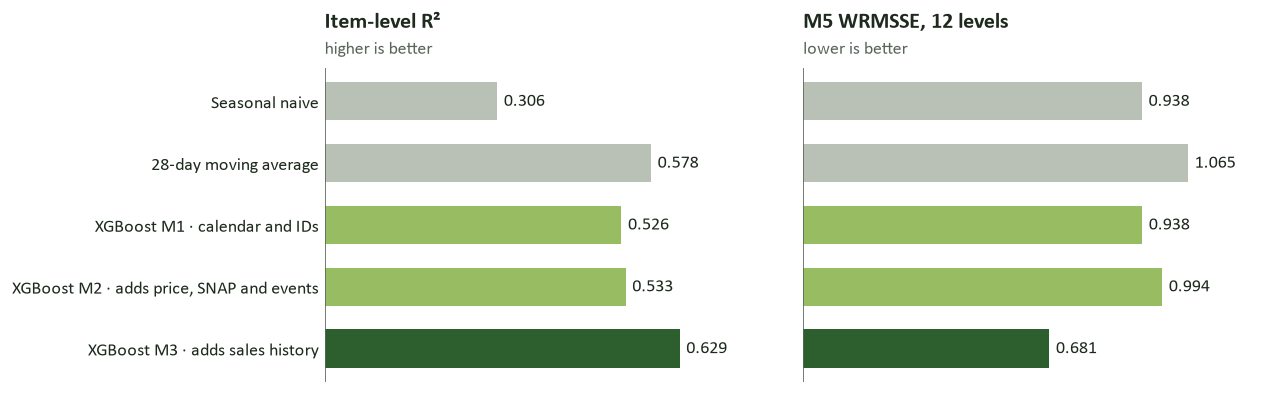

In [5]:
def bar_panels(rows, df, colors, panels, figsize=(10, 3.4)):
    """Two aligned horizontal bar panels sharing the model labels."""
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True, gridspec_kw={"wspace": 0.06})
    y = np.arange(len(rows))
    for ax, (col, head, sense, xmax) in zip(axes, panels):
        vals = df.loc[rows, col].to_numpy()
        ax.barh(y, vals, height=0.62, color=colors, zorder=2)
        for yy, v in zip(y, vals):
            ax.text(v + xmax * 0.015, yy, f"{v:.3f}", va="center", color=INK)
        ax.set_xlim(0, xmax)
        ax.set_xticks([])
        ax.grid(False)
        ax.spines[["left", "bottom"]].set_visible(False)
        ax.axvline(0, color=GRAY, lw=1)
        ax.set_title(head, pad=24)
        ax.text(0, 1.03, sense, transform=ax.transAxes, color=GRAY, va="bottom")
    axes[0].set_yticks(y, [NAME[r] for r in rows])
    axes[0].invert_yaxis()
    return fig


rows = ROWS["28-day"]
fig = bar_panels(rows, overall["28-day"], [BASE, BASE, LGREEN, LGREEN, GREEN],
                 [("R2", "Item-level R²", "higher is better", 0.8),
                  ("WRMSSE", "M5 WRMSSE, 12 levels", "lower is better", 1.25)])
plt.show()

Calendar, price, SNAP and event features alone (M1, M2) do not beat a 28-day moving average on R². Adding sales history (M3) is the step that makes the model useful: R² rises from 0.533 to 0.629 and WRMSSE falls from 0.994 to 0.681.

## 4. Accuracy at each level of the M5 hierarchy
WRMSSE averages 12 levels, from total chain sales down to single item–store series. Lower is better at every level.

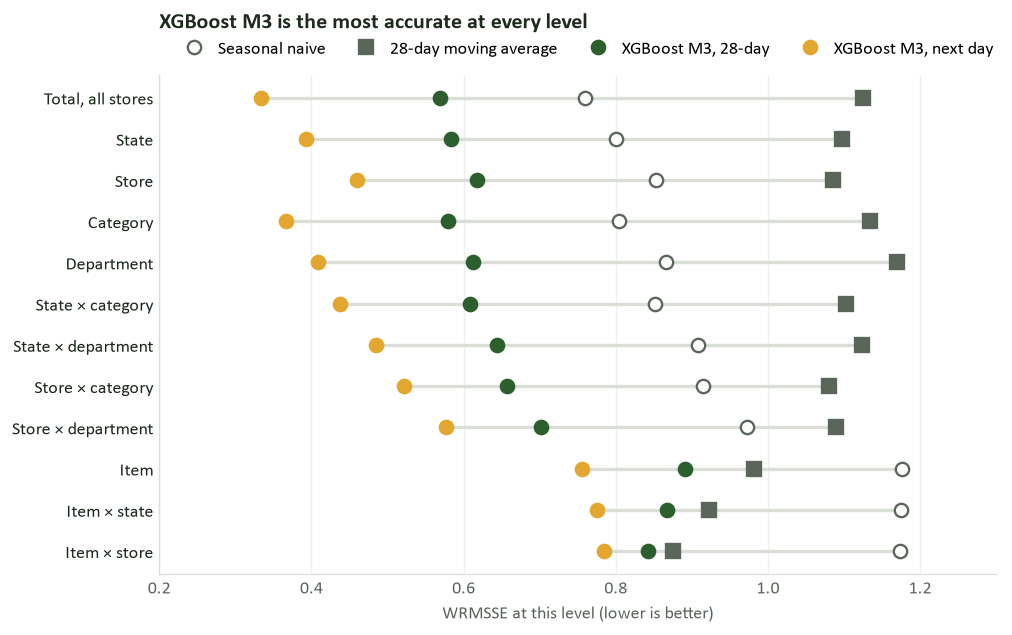

,Seasonal naive,28-day moving average,"XGBoost M3, 28-day","XGBoost M3, next day"
level,,,,
"Total, all stores",0.760,1.125,0.569,0.334
State,0.800,1.098,0.584,0.393
Store,0.852,1.086,0.618,0.460
Category,0.804,1.134,0.579,0.366
Department,0.866,1.169,0.613,0.409
State × category,0.852,1.102,0.608,0.438
State × department,0.908,1.123,0.644,0.485
Store × category,0.915,1.081,0.658,0.522
Store × department,0.973,1.089,0.702,0.577


In [6]:
LEVEL = {"L1_total": "Total, all stores", "L2_state": "State", "L3_store": "Store", "L4_cat": "Category",
         "L5_dept": "Department", "L6_state_cat": "State × category", "L7_state_dept": "State × department",
         "L8_store_cat": "Store × category", "L9_store_dept": "Store × department", "L10_item": "Item",
         "L11_item_state": "Item × state", "L12_item_store": "Item × store"}
lvl = read("wrmsse_by_level.csv")

fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(len(LEVEL))
vals = np.column_stack([lvl[run][col].to_numpy() for _, run, col, _ in SERIES])
ax.hlines(y, vals.min(axis=1), vals.max(axis=1), color=RULE, lw=2, zorder=1)
for (label, run, col, st), v in zip(SERIES, vals.T):
    ax.plot(v, y, ls="", ms=8, mew=1.4, mec=st["color"], color=st["color"], marker=st["marker"],
            mfc=st["mfc"], label=label, zorder=3)
ax.set_yticks(y, [LEVEL[i] for i in lvl["28-day"].index])
ax.invert_yaxis()
ax.set_xlim(0.2, 1.3)
ax.set_xlabel("WRMSSE at this level (lower is better)")
ax.grid(axis="y", visible=False)
ax.set_title("XGBoost M3 is the most accurate at every level", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, handletextpad=0.3, columnspacing=1.2)
plt.show()

show = pd.DataFrame({label: lvl[run][col] for label, run, col, _ in SERIES}).rename(index=LEVEL)
display(show.style.format("{:.3f}"))

Errors grow from totals down to single items for every model. Re-forecasting daily helps most where sales are added up: it cuts M3's WRMSSE by 41% for total chain sales but by 7% for single item–store series.

## 5. Accuracy across the test year

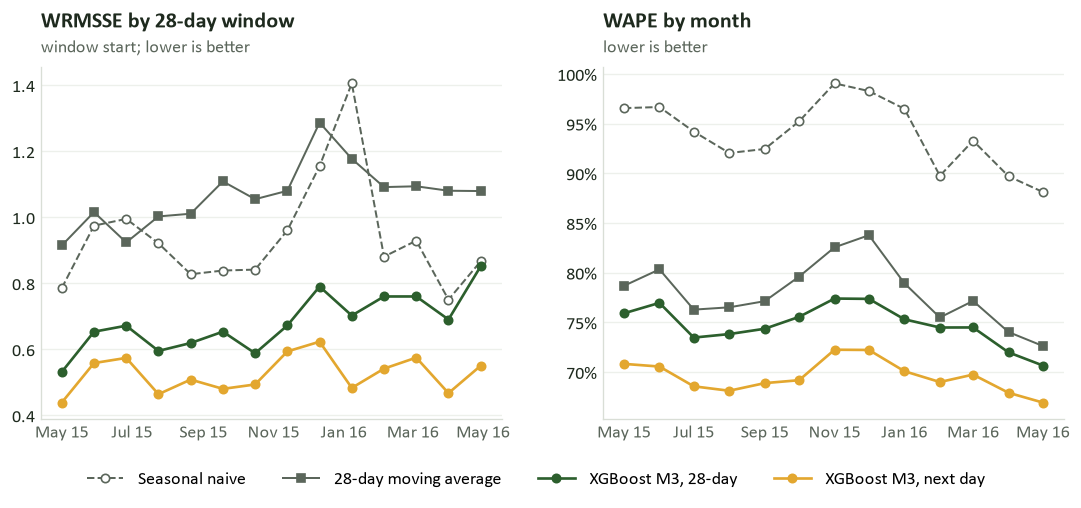

M3 (28-day) beats seasonal naive in all 14 windows: True
M3 (28-day) beats the 28-day moving average in all 14 windows: True


In [7]:
win = read("wrmsse_by_window.csv")
mon = read("wape_by_month.csv")
starts = pd.Timestamp("2015-05-01") + pd.to_timedelta(28 * np.arange(14), unit="D")
months = pd.to_datetime(mon["28-day"].index)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.22})
for label, run, col, st in SERIES:
    kw = dict(color=st["color"], ls=st["ls"], lw=1.6 if "XGBoost" in label else 1.2,
              marker=st["marker"], mfc=st["mfc"], mec=st["color"], ms=5, label=label)
    axes[0].plot(starts, win[run][col].to_numpy(), **kw)
    axes[1].plot(months, mon[run][col].to_numpy(), **kw)
axes[0].set_title("WRMSSE by 28-day window", pad=24)
axes[0].text(0, 1.03, "window start; lower is better", transform=axes[0].transAxes, color=GRAY, va="bottom")
axes[1].set_title("WAPE by month", pad=24)
axes[1].text(0, 1.03, "lower is better", transform=axes[1].transAxes, color=GRAY, va="bottom")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", labelsize=10.5)
    ax.grid(axis="x", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08))
plt.show()

print("M3 (28-day) beats seasonal naive in all 14 windows:",
      bool((win["28-day"].xgb_M3_full < win["28-day"].naive_lag28).all()))
print("M3 (28-day) beats the 28-day moving average in all 14 windows:",
      bool((win["28-day"].xgb_M3_full < win["28-day"].ma_28).all()))

## 6. Daily total sales: actual against forecast

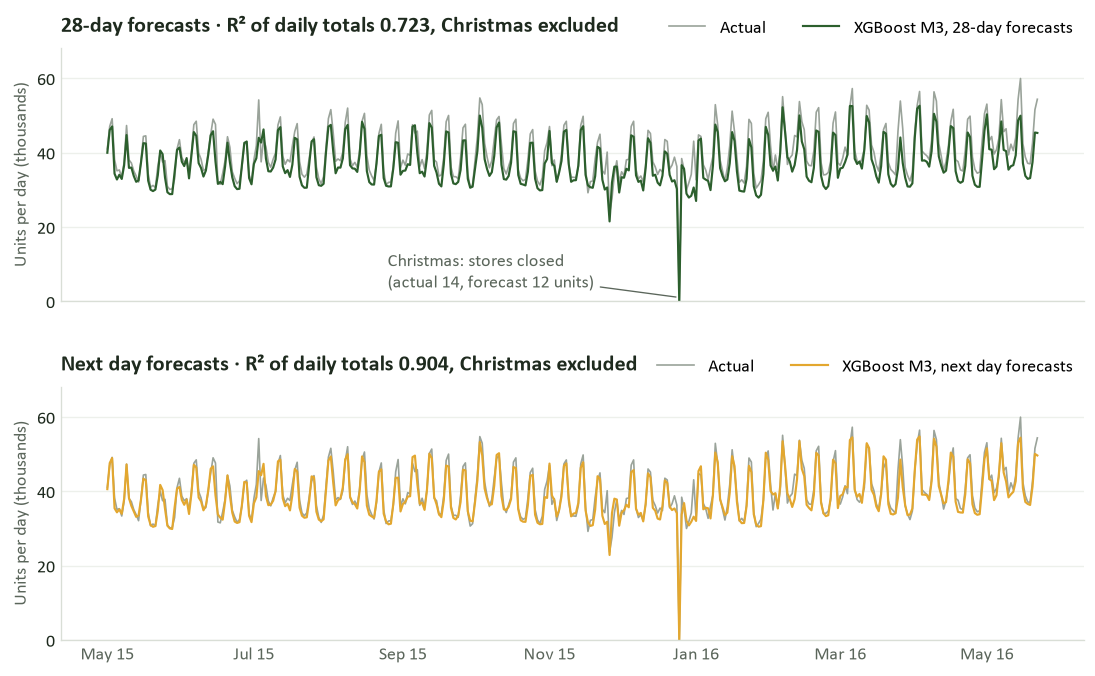

28-day: forecast below actual on 93% of days; total units forecast vs actual -6.6%
Next day: forecast below actual on 71% of days; total units forecast vs actual -2.0%


In [8]:
daily = read("daily_totals.csv", parse_dates=True)
xmas = pd.Timestamp("2015-12-25")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, sharey=True, gridspec_kw={"hspace": 0.34})
for ax, (run, c) in zip(axes, [("28-day", GREEN), ("Next day", AMBER)]):
    d = daily[run]
    r2 = overall[run].loc["xgb_M3_full", "Daily_total_R2_exXmas"]
    ax.plot(d.index, d["y"] / 1e3, color="#9AA39A", lw=1.0, label="Actual")
    ax.plot(d.index, d["xgb_M3_full"] / 1e3, color=c, lw=1.3, label=f"XGBoost M3, {run.lower()} forecasts")
    ax.set_title(f"{run} forecasts · R² of daily totals {r2:.3f}, Christmas excluded")
    ax.set_ylabel("Units per day (thousands)")
    ax.set_ylim(0, 68)
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2, borderaxespad=0.2)
    ax.grid(axis="x", visible=False)
axes[0].annotate(f"Christmas: stores closed\n(actual {daily['28-day'].loc[xmas, 'y']:.0f}, "
                 f"forecast {daily['28-day'].loc[xmas, 'xgb_M3_full']:.0f} units)",
                 xy=(xmas, 1), xytext=(-175, 6), textcoords="offset points", color=GRAY, fontsize=10.5,
                 arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
plt.show()

for run in RUN:
    d = daily[run].drop(xmas)
    print(f"{run}: forecast below actual on {(d['y'] > d['xgb_M3_full']).mean():.0%} of days; "
          f"total units forecast vs actual {d['xgb_M3_full'].sum() / d['y'].sum() - 1:+.1%}")

M3 learned that stores close on Christmas Day from the training years; the 28-day moving average forecast about 36,700 units that day. Over the year, the 28-day forecasts sit below actual sales on more than 9 days in 10, which adds up to a 6.6% shortfall in total units. Daily re-forecasting reduces it to 2.0%.

## 7. Which features the model relies on

Share of total gain by feature group (M3)


,28-day,Next day
Sales history,93.3%,95.6%
"Calendar, IDs and days ahead",4.0%,2.3%
"Price, SNAP and events",2.7%,2.1%


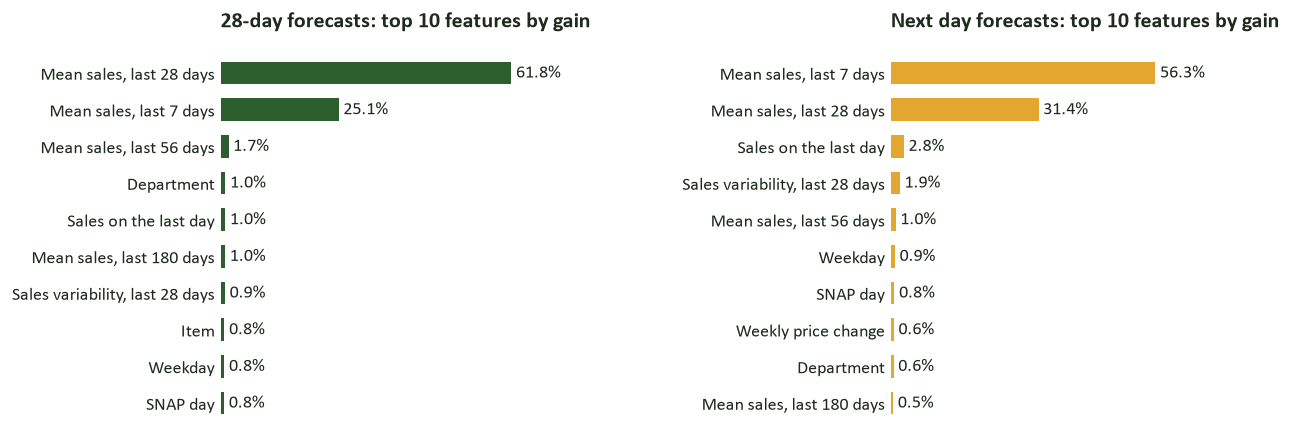

In [9]:
FEAT = {"rmean_7": "Mean sales, last 7 days", "rmean_28": "Mean sales, last 28 days",
        "rmean_56": "Mean sales, last 56 days", "rmean_180": "Mean sales, last 180 days",
        "rstd_28": "Sales variability, last 28 days", "olag_1": "Sales on the last day",
        "olag_2": "Sales 2 days back", "olag_7": "Sales 7 days back", "olag_14": "Sales 14 days back",
        "olag_28": "Sales 28 days back", "olag_364": "Sales 1 year back", "lag_28": "Sales 28 days before target",
        "dept_id": "Department", "item_id": "Item", "store_id": "Store", "wday": "Weekday", "month": "Month",
        "year": "Year", "week": "Week of year", "dom": "Day of month", "days_ahead": "Days ahead",
        "snap": "SNAP day", "sell_price": "Price", "price_chg_wk": "Weekly price change",
        "price_rel_max": "Price vs. highest so far", "price_rel_mean": "Price vs. average so far",
        "event_name": "Event name", "event_type": "Event type", "is_event": "Event day"}


def group(f):
    if f.startswith(("rmean_", "rstd_", "olag_", "lag_")):
        return "Sales history"
    if f.startswith(("sell_price", "price_", "snap", "is_event", "event_")):
        return "Price, SNAP and events"
    return "Calendar, IDs and days ahead"


imp = {k: v["gain_share"] for k, v in read("feature_importance.csv").items()}
shares = pd.DataFrame({k: s.groupby(s.index.map(group)).sum() for k, s in imp.items()})
print("Share of total gain by feature group (M3)")
display(shares.sort_values("28-day", ascending=False).style.format("{:.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.9})
for ax, (run, c) in zip(axes, [("28-day", GREEN), ("Next day", AMBER)]):
    top = imp[run].head(10)[::-1]
    ax.barh([FEAT[f] for f in top.index], top.to_numpy(), height=0.62, color=c, zorder=2)
    for yy, v in enumerate(top.to_numpy()):
        ax.text(v + 0.01, yy, f"{v:.1%}", va="center", color=INK)
    ax.set_xlim(0, 0.75)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_title(f"{run} forecasts: top 10 features by gain")
plt.show()

Recent average sales carry the model. The 28-day and 7-day means take 87% of the gain in both schedules; price, SNAP and events together take under 3%. With a 28-day forecast the 28-day mean leads; with a daily refresh the 7-day mean leads.

## 8. Where forecasting is hard (28-day forecasts)

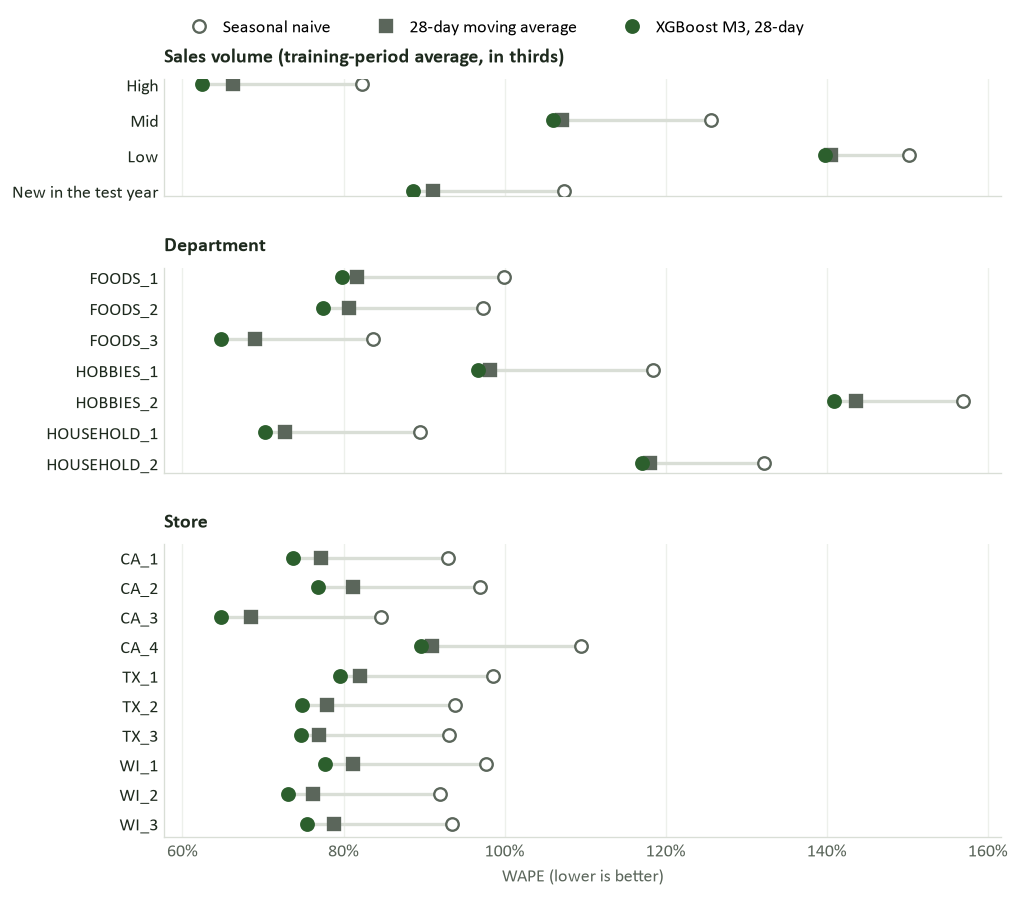

In [10]:
SEG = [("Sales volume (training-period average, in thirds)", "volume",
        {"high": "High", "mid": "Mid", "low": "Low", "new_item": "New in the test year"}),
       ("Department", "dept", None), ("Store", "store", None)]
segs = [(title, read(f"wape_by_{key}.csv")["28-day"], names) for title, key, names in SEG]
segs = [(t, d.loc[list(n)].rename(index=n) if n else d, n) for t, d, n in segs]

fig, axes = plt.subplots(3, 1, figsize=(9, 8.2), sharex=True,
                         gridspec_kw={"height_ratios": [len(d) for _, d, _ in segs], "hspace": 0.35})
for ax, (title, d, _) in zip(axes, segs):
    y = np.arange(len(d))
    cols = [s for s in SERIES if s[1] == "28-day"]
    v = np.column_stack([d[col].to_numpy() for _, _, col, _ in cols])
    ax.hlines(y, v.min(axis=1), v.max(axis=1), color=RULE, lw=2, zorder=1)
    for (label, _, col, st), vv in zip(cols, v.T):
        ax.plot(vv, y, ls="", ms=7.5, mew=1.4, marker=st["marker"], mfc=st["mfc"], mec=st["color"],
                label=label, zorder=3)
    ax.set_yticks(y, d.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=12)
axes[-1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[-1].set_xlabel("WAPE (lower is better)")
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.22), ncol=3, handletextpad=0.3)
plt.show()

M3 has the lowest WAPE in every segment, but the gap to the baselines is small where demand is sparse. Low-volume items (WAPE 140%) and the hobbies department HOBBIES_2 (141%) are hard for every model; high-volume items (62%) and FOODS_3 (65%) are much easier. Store CA_4 is the hardest store (90%) and CA_3 the easiest (65%). Errors peak in November and December.

## Key findings

1. **Sales history is what makes XGBoost work.** Calendar, price and event features alone do not beat a 28-day moving average. Adding sales history raises R² from 0.533 to 0.629 and cuts WRMSSE from 0.994 to 0.681, and recent average sales take 87% of the model's gain.
2. **M3 beats both baselines on all four metrics, at all 12 levels and in all 14 test windows.** Against seasonal naive, WRMSSE falls by 27% and MAE by 0.25 units per item–day.
3. **Totals are far easier than single items.** M3's WRMSSE is 0.57 for total chain sales and 0.84 for single item–store series; low-volume items stay hard for every model.
4. **Re-forecasting daily is the next big gain.** The same model, updated every day, reaches R² 0.706, MAE 0.911, WAPE 69.5% and WRMSSE 0.525, the highest R² and lowest WRMSSE of any run on the full panel. The gain is largest for totals (−41% WRMSSE on chain sales).
5. **The 28-day forecasts run low.** They forecast 6.6% fewer units than were sold, falling short on more than 9 days in 10; daily re-forecasting reduces that to 2.0%. XGBoost needs no GPU: both schedules trained on CPU.